# Physics-Informed Neural Networks (PINN) u PyTorch-u

Primeri iz notebook-a **17_PINN.ipynb** (TensorFlow), prepisani u **PyTorch**.

| Lab | Problem | Implementacija |
|---|---|---|
| 1 | du/dt = cos(2πt), u(0) = 1 | PINN implementiran ručno, u čistom PyTorch-u |
| 2 | isti problem kao Lab 1 | biblioteka DeepXDE sa PyTorch backendom |
| 3 | Ojlerova greda, y'''' + 1 = 0 | ručno, u čistom PyTorch-u |
| 4 | Navije–Stoksove jednačine (tok između ploča) | ručno, u čistom PyTorch-u, uz analizu gubitka po delovima i po tačkama |

## TensorFlow → PyTorch: šta je šta

| Operacija | TensorFlow (original) | PyTorch |
|---|---|---|
| mreža | `tf.keras.Sequential([Dense(32, 'tanh'), Dense(1)])` | `nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 1))` |
| „prati izvod po t“ | `tape.watch(t)` | `t.requires_grad_(True)` |
| izvod du/dt | `tape.gradient(u, t)` | `torch.autograd.grad(u, t, ..., create_graph=True)` |
| izvod gubitka po težinama | `tape.gradient(loss, NN.trainable_variables)` | `loss.backward()` |
| korak optimizera | `optm.apply_gradients(...)` | `optimizer.step()` (pre toga `optimizer.zero_grad()`) |

**`create_graph=True`** je ekvivalent dve ugnježdene trake u TensorFlow-u: gubitak sadrži izvod du/dt, pa PyTorch mora da zapamti kako je on nastao da bi kasnije mogao da izračuna i izvod gubitka po težinama.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Uređaj:', device)

Uređaj: cuda


In [2]:
def izvod(y, x):
    # Izvod izlaza y po ulazu x, preko automatske diferencijacije.
    # create_graph=True: omogućava diferenciranje samog izvoda (drugi izvod, trening).
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

---
# Lab 1: PINN napisan ručno

**Problem:**

$$\frac{du}{dt} = \cos(2\pi t), \qquad u(0) = 1, \qquad t \in [0, 2]$$

**Tačno rešenje** (služi samo za proveru na kraju):

$$u(t) = \frac{1}{2\pi}\sin(2\pi t) + 1$$

**Gubitak:**

$$\mathcal{L} = \underbrace{\frac{1}{n}\sum_i \left(\frac{dNN(t_i)}{dt} - \cos 2\pi t_i\right)^2}_{\text{da li kriva poštuje pravilo}} + \underbrace{\left(NN(0) - 1\right)^2}_{\text{da li kreće od 1}}$$

### 1.1 Mreža i optimizer

In [3]:
NN = nn.Sequential(
    nn.Linear(1, 32),   # ulaz: jedan broj t → 32 neurona
    nn.Tanh(),          # glatka aktivacija (ima lepe izvode, za razliku od ReLU)
    nn.Linear(32, 1)    # izlaz: jedan broj u
).to(device)

print(NN)

optm = torch.optim.Adam(NN.parameters(), lr=0.001)

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=1, bias=True)
)


### 1.2 Gubitak

1. Mreža za svako t daje vrednost u.
2. Automatskim diferenciranjem računa se izvod du/dt.
3. Izvod se poredi sa desnom stranom jednačine, cos(2πt); razlika je **rezidual**.
4. Proverava se početni uslov u(0) = 1.

In [4]:
def ode_system(t, net):
    t = t.clone().requires_grad_(True)          # = tape.watch(t)

    u = net(t)                                  # mreža crta krivu
    u_t = izvod(u, t)                           # du/dt (izvod po ULAZU)

    ode_loss = u_t - torch.cos(2 * np.pi * t)   # rezidual: koliko kriva krši pravilo

    t_0 = torch.zeros((1, 1), device=device)
    IC_loss = net(t_0) - 1.0                    # početni uslov: u(0) mora biti 1

    total_loss = torch.mean(ode_loss**2) + torch.mean(IC_loss**2)
    return total_loss

### 1.3 Trening

`train_t` su **kolokacione tačke**: 30 nasumičnih trenutaka između 0 i 2 u kojima se proverava jednačina. To **nisu merenja**: mreža nikada ne vidi prave vrednosti u.

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


0 1.528254747390747
1000 0.45852339267730713
2000 0.23079141974449158
3000 0.00999264232814312
4000 0.001524388324469328
5000 0.001021770527586341


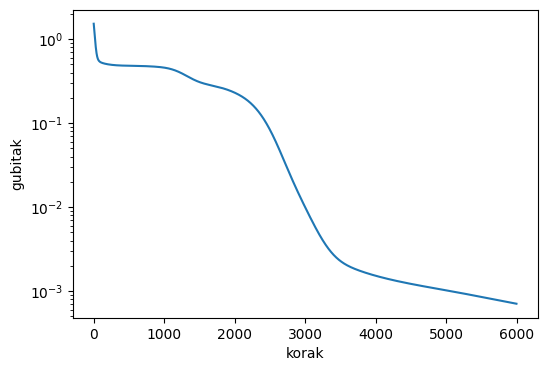

In [5]:
train_t = torch.rand(30, 1, device=device) * 2
train_loss_record = []

for itr in range(6000):
    optm.zero_grad()                       # brisanje gradijenata iz prethodnog koraka
    train_loss = ode_system(train_t, NN)   # računanje gubitka
    train_loss.backward()                  # izvod gubitka po TEŽINAMA (dL/dθ)
    optm.step()                            # ažuriranje težina

    train_loss_record.append(train_loss.item())
    if itr % 1000 == 0:
        print(itr, train_loss.item())

plt.figure(figsize=(6, 4))
plt.plot(train_loss_record)
plt.yscale('log')
plt.xlabel('korak')
plt.ylabel('gubitak')
plt.show()

### 1.4 Rezultat: PINN prema tačnom rešenju

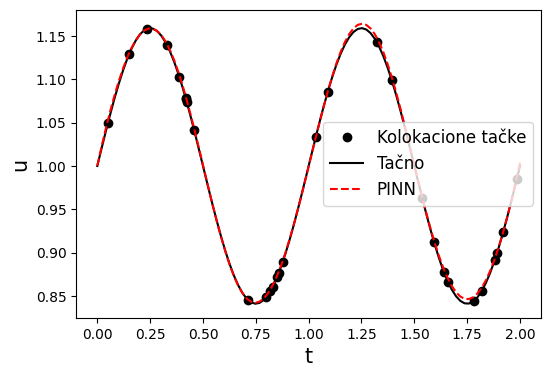

Najveća greška: 0.00537603936898301


In [6]:
test_t = np.linspace(0, 2, 100)
train_t_np = train_t.cpu().numpy()

train_u = np.sin(2*np.pi*train_t_np) / (2*np.pi) + 1   # samo za crtanje tačaka na pravoj krivoj
true_u = np.sin(2*np.pi*test_t) / (2*np.pi) + 1

with torch.no_grad():
    pred_u = NN(torch.tensor(test_t, dtype=torch.float32, device=device).reshape(-1, 1)).cpu().numpy().ravel()

plt.figure(figsize=(6, 4))
plt.plot(train_t_np, train_u, 'ok', label='Kolokacione tačke')
plt.plot(test_t, true_u, '-k', label='Tačno')
plt.plot(test_t, pred_u, '--r', label='PINN')
plt.legend(fontsize=12)
plt.xlabel('t', fontsize=15)
plt.ylabel('u', fontsize=15)
plt.show()

print('Najveća greška:', np.max(np.abs(pred_u - true_u)))

---
# Lab 2: isti problem preko DeepXDE (PyTorch backend)

DeepXDE automatski formira gubitak i petlju treninga; potrebno je samo opisati problem.

Backend se bira **pre prvog** `import deepxde`, preko promenljive okruženja `DDE_BACKEND`. Ako je DeepXDE u istoj sesiji već uvezen sa drugim backendom, potrebno je restartovati sesiju (Runtime → Restart session) i ponovo izvršiti ćelije, uključujući importe na vrhu.

| Lab 1 (ručno) | Lab 2 (DeepXDE) |
|---|---|
| `izvod(u, t)` | `dde.grad.jacobian(u, t)` |
| `IC_loss = net(t_0) - 1` | `dde.icbc.IC(geom, lambda t: 1, ...)` |
| `train_t` (30 tačaka) | `num_domain = 30` |
| `nn.Sequential(...)` | `dde.nn.FNN([1, 32, 1], 'tanh', ...)` |
| trening petlja | `model.train(iterations=6000)` |

In [7]:
!pip install -q deepxde

In [8]:
import os
os.environ['DDE_BACKEND'] = 'pytorch'

import deepxde as dde
print('DeepXDE backend:', dde.backend.backend_name)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


DeepXDE backend: pytorch


In [9]:
def ode_system_dde(t, u):
    du_t = dde.grad.jacobian(u, t)
    return du_t - torch.cos(2 * np.pi * t)

def initial(t, on_initial):
    return on_initial and np.isclose(t[0], 0)

def true_solution(t):
    return np.sin(2*np.pi*t) / (2*np.pi) + 1

geom = dde.geometry.TimeDomain(0, 2)
ic = dde.icbc.IC(geom, lambda t: 1, initial)

data = dde.data.PDE(geom,
                    ode_system_dde,
                    ic,
                    num_domain=30,
                    num_boundary=2,
                    solution=true_solution,
                    num_test=100)

net = dde.nn.FNN([1] + [32] + [1], 'tanh', 'Glorot uniform')

model = dde.Model(data, net)
model.compile('adam', lr=0.001, metrics=['l2 relative error'])

Compiling model...
'compile' took 0.000938 s



Training model...

Step      Train loss              Test loss               Test metric   
0         [5.98e-01, 1.00e+00]    [5.98e-01, 1.00e+00]    [7.16e-01]    
1000      [4.79e-01, 2.39e-04]    [4.75e-01, 2.39e-04]    [1.12e-01]    
2000      [2.14e-01, 2.30e-05]    [2.26e-01, 2.30e-05]    [6.98e-02]    
3000      [5.75e-02, 5.04e-09]    [6.37e-02, 5.04e-09]    [3.04e-02]    
4000      [5.53e-03, 6.74e-08]    [5.24e-03, 6.74e-08]    [7.68e-03]    
5000      [2.27e-03, 2.27e-11]    [1.72e-03, 2.27e-11]    [3.81e-03]    
6000      [1.45e-03, 1.34e-08]    [1.08e-03, 1.34e-08]    [2.82e-03]    

Best model at step 6000:
  train loss: 1.45e-03
  test loss: 1.08e-03
  test metric: [2.82e-03]

'train' took 25.816127 s



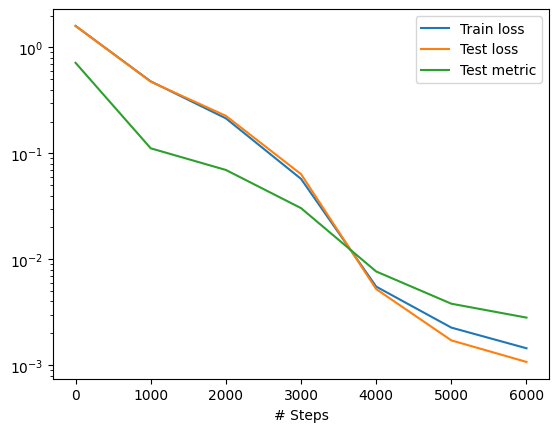

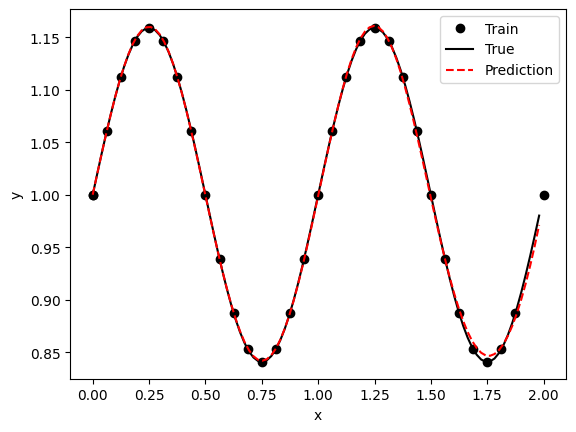

In [10]:
losshistory, train_state = model.train(iterations=6000)
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

---
# Lab 3: Ojlerova greda (savijanje grede)

**Jednačina** (greda dužine 1, pod ravnomernim opterećenjem):

$$\frac{d^4 y}{dx^4} + 1 = 0, \qquad x \in [0, 1]$$

**Granični uslovi:**

| uslov | značenje |
|---|---|
| y(0) = 0 | levi kraj je pričvršćen, ne pomera se |
| y'(0) = 0 | levi kraj je uklješten, ne naginje se |
| y''(1) = 0 | desni kraj je slobodan: nema momenta savijanja |
| y'''(1) = 0 | desni kraj je slobodan: nema sile smicanja |

**Tačno rešenje:**

$$y(x) = -\frac{x^4}{24} + \frac{x^3}{6} - \frac{x^2}{4}$$

Jedina novina u odnosu na Lab 1 su **viši izvodi**: funkcija `izvod` primenjuje se četiri puta zaredom.

Ovo je zapravo **ODE** (zavisi samo od x), iako se u originalu funkcija zove `pde`.

In [11]:
torch.manual_seed(0)

net_beam = nn.Sequential(
    nn.Linear(1, 20), nn.Tanh(),
    nn.Linear(20, 20), nn.Tanh(),
    nn.Linear(20, 20), nn.Tanh(),
    nn.Linear(20, 1)
).to(device)

optm_beam = torch.optim.Adam(net_beam.parameters(), lr=0.001)

x_domain = torch.rand(10, 1, device=device)   # 10 kolokacionih tačaka unutar grede (kao num_domain=10)
x_left = torch.zeros(1, 1, device=device)     # levi kraj, x = 0
x_right = torch.ones(1, 1, device=device)     # desni kraj, x = 1

def beam_loss(net):
    # 1) jednačina unutar grede
    x = x_domain.clone().requires_grad_(True)
    y = net(x)
    y_x = izvod(y, x)
    y_xx = izvod(y_x, x)
    y_xxx = izvod(y_xx, x)
    y_xxxx = izvod(y_xxx, x)
    pde = y_xxxx + 1

    # 2) levi kraj: y(0) = 0 i y'(0) = 0
    xl = x_left.clone().requires_grad_(True)
    yl = net(xl)
    yl_x = izvod(yl, xl)

    # 3) desni kraj: y''(1) = 0 i y'''(1) = 0
    xr = x_right.clone().requires_grad_(True)
    yr = net(xr)
    yr_xx = izvod(izvod(yr, xr), xr)
    yr_xxx = izvod(yr_xx, xr)

    return (torch.mean(pde**2)
            + torch.mean(yl**2) + torch.mean(yl_x**2)
            + torch.mean(yr_xx**2) + torch.mean(yr_xxx**2))

loss_record_beam = []
for itr in range(5000):
    optm_beam.zero_grad()
    loss = beam_loss(net_beam)
    loss.backward()
    optm_beam.step()
    loss_record_beam.append(loss.item())
    if itr % 1000 == 0:
        print(itr, loss.item())

0 1.192714810371399
1000 0.0002912725612986833
2000 1.3397572729445528e-05
3000 7.5112393460585736e-06
4000 5.213736585574225e-06


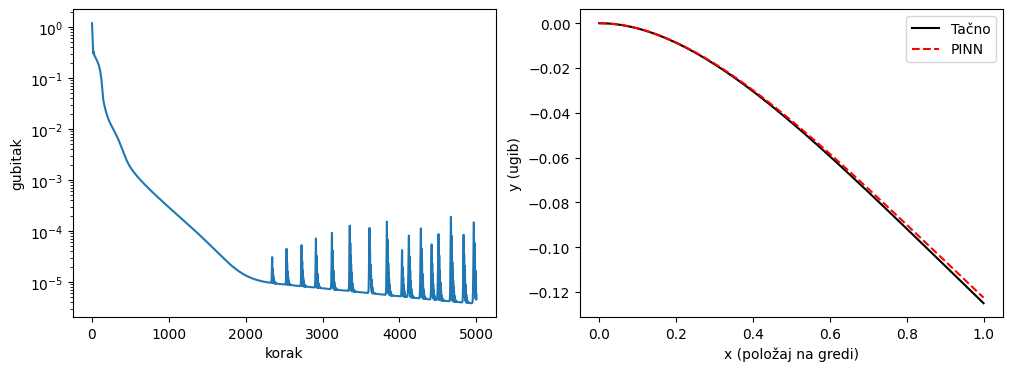

Relativna L2 greška: 0.01924303046291151


In [12]:
x_test = np.linspace(0, 1, 100)
y_true = -(x_test**4)/24 + x_test**3/6 - x_test**2/4

with torch.no_grad():
    y_pred = net_beam(torch.tensor(x_test, dtype=torch.float32, device=device).reshape(-1, 1)).cpu().numpy().ravel()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss_record_beam)
ax[0].set_yscale('log')
ax[0].set_xlabel('korak')
ax[0].set_ylabel('gubitak')

ax[1].plot(x_test, y_true, '-k', label='Tačno')
ax[1].plot(x_test, y_pred, '--r', label='PINN')
ax[1].set_xlabel('x (položaj na gredi)')
ax[1].set_ylabel('y (ugib)')
ax[1].legend()
plt.show()

print('Relativna L2 greška:', np.linalg.norm(y_pred - y_true) / np.linalg.norm(y_true))

---
# Lab 4: Navije–Stoksove jednačine (tok između dve ploče)

Tečnost ulazi s leve strane ravnomernom brzinom, lepi se za zidove i postepeno formira **paraboličan profil**: najbrža je u sredini, a uz zidove stoji.

**Mreža:** ulaz (x, y), izlaz (u, v, p):
- u: brzina napred (pravac x)
- v: brzina gore-dole (pravac y)
- p: pritisak

**Tri jednačine** (sve tri treba da budu 0 u svakoj tački):

$$
\begin{aligned}
u\,u_x + v\,u_y + \tfrac{1}{\rho}p_x - \nu(u_{xx} + u_{yy}) &= 0 \quad\text{(kretanje napred)}\\
u\,v_x + v\,v_y + \tfrac{1}{\rho}p_y - \nu(v_{xx} + v_{yy}) &= 0 \quad\text{(kretanje gore-dole)}\\
u_x + v_y &= 0 \quad\text{(ništa ne nestaje)}
\end{aligned}
$$

**Šest graničnih uslova:**

| ivica | uslovi |
|---|---|
| zidovi (y = ±0,5) | u = 0, v = 0 |
| ulaz (x = −1) | u = 1, v = 0 |
| izlaz (x = 1) | p = 0, v = 0 |

### 4.1 Parametri

In [13]:
rho = 1      # gustina
mu = 1       # viskoznost
u_in = 1     # ulazna brzina
D = 1        # razmak između ploča
L = 2        # dužina kanala
nu = mu / rho

### 4.2 Tačke (kolokacione i granične)

- **2000 tačaka unutra**, gde se proveravaju jednačine. Biraju se Sobolovim nizom, koji tačke raspoređuje ravnomerno (kao Hammersley u DeepXDE-u).
- **200 tačaka na ivicama**: po 70 na svakom zidu, 30 na ulazu i 30 na izlazu.

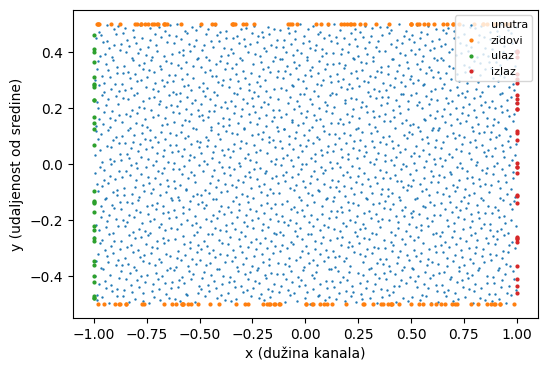

In [14]:
torch.manual_seed(0)

sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=0)
s = sobol.draw(2000)
X_domain = torch.stack([s[:, 0] * L - L/2, s[:, 1] * D - D/2], dim=1)

def tacke_na_liniji(n, x=None, y=None):
    # n tačaka na vertikalnoj liniji (zadato x) ili horizontalnoj liniji (zadato y)
    if x is not None:
        yy = torch.rand(n, 1) * D - D/2
        return torch.cat([torch.full((n, 1), float(x)), yy], dim=1)
    xx = torch.rand(n, 1) * L - L/2
    return torch.cat([xx, torch.full((n, 1), float(y))], dim=1)

X_wall = torch.cat([tacke_na_liniji(70, y=-D/2), tacke_na_liniji(70, y=D/2)])   # donji i gornji zid
X_inlet = tacke_na_liniji(30, x=-L/2)                                            # ulaz
X_outlet = tacke_na_liniji(30, x=L/2)                                            # izlaz

X_domain, X_wall, X_inlet, X_outlet = [t.to(device) for t in (X_domain, X_wall, X_inlet, X_outlet)]

plt.figure(figsize=(6, 4))
plt.scatter(X_domain[:, 0].cpu(), X_domain[:, 1].cpu(), s=0.5, label='unutra')
for X, lbl in [(X_wall, 'zidovi'), (X_inlet, 'ulaz'), (X_outlet, 'izlaz')]:
    plt.scatter(X[:, 0].cpu(), X[:, 1].cpu(), s=4, label=lbl)
plt.xlabel('x (dužina kanala)')
plt.ylabel('y (udaljenost od sredine)')
plt.legend(loc='upper right', fontsize=8)
plt.show()

### 4.3 Mreža i fizika

`izvod(u, X)` vraća **oba** prva izvoda odjednom, jer X ima dve kolone: kolona 0 je ∂u/∂x, a kolona 1 je ∂u/∂y. Drugi izvod se dobija ponovnim diferenciranjem jedne od tih kolona.

In [15]:
torch.manual_seed(0)

layers = [nn.Linear(2, 64), nn.Tanh()]
for _ in range(4):
    layers += [nn.Linear(64, 64), nn.Tanh()]
layers += [nn.Linear(64, 3)]
net_ns = nn.Sequential(*layers).to(device)   # 2 → 64×5 → 3

def pde(X):
    X = X.clone().requires_grad_(True)
    Y = net_ns(X)
    u, v, p = Y[:, 0:1], Y[:, 1:2], Y[:, 2:3]

    # prvi izvodi: [:, 0:1] je po x, [:, 1:2] je po y
    du = izvod(u, X); du_x, du_y = du[:, 0:1], du[:, 1:2]
    dv = izvod(v, X); dv_x, dv_y = dv[:, 0:1], dv[:, 1:2]
    dp = izvod(p, X); dp_x, dp_y = dp[:, 0:1], dp[:, 1:2]

    # drugi izvodi
    du_xx = izvod(du_x, X)[:, 0:1]
    du_yy = izvod(du_y, X)[:, 1:2]
    dv_xx = izvod(dv_x, X)[:, 0:1]
    dv_yy = izvod(dv_y, X)[:, 1:2]

    pde_u = u*du_x + v*du_y + 1/rho * dp_x - nu*(du_xx + du_yy)
    pde_v = u*dv_x + v*dv_y + 1/rho * dp_y - nu*(dv_xx + dv_yy)
    pde_cont = du_x + dv_y
    return pde_u, pde_v, pde_cont

def mse(a):
    return torch.mean(a**2)

def ukupan_gubitak():
    pde_u, pde_v, pde_cont = pde(X_domain)
    Yw, Yi, Yo = net_ns(X_wall), net_ns(X_inlet), net_ns(X_outlet)

    loss_pde = mse(pde_u) + mse(pde_v) + mse(pde_cont)          # L_G
    loss_bc = (mse(Yw[:, 0]) + mse(Yw[:, 1])                    # zidovi: u = 0, v = 0
               + mse(Yi[:, 0] - u_in) + mse(Yi[:, 1])           # ulaz:   u = 1, v = 0
               + mse(Yo[:, 2]) + mse(Yo[:, 1]))                 # izlaz:  p = 0, v = 0
    return loss_pde + loss_bc, loss_pde, loss_bc                # L_total = L_G + L_BC

### 4.4 Trening (Adam)

Na GPU-u ovo traje par minuta, a na CPU-u znatno duže.

     0  ukupno 8.8949e-01  fizika 1.3913e-03  ivice 8.8810e-01
  1000  ukupno 1.0680e-01  fizika 1.3199e-02  ivice 9.3600e-02
  2000  ukupno 8.3745e-02  fizika 7.7482e-03  ivice 7.5996e-02
  3000  ukupno 7.1987e-02  fizika 6.4967e-03  ivice 6.5490e-02
  4000  ukupno 7.0507e-02  fizika 5.8851e-03  ivice 6.4622e-02
  5000  ukupno 5.7116e-02  fizika 4.2130e-03  ivice 5.2903e-02
  6000  ukupno 5.3542e-02  fizika 4.2486e-03  ivice 4.9293e-02
  7000  ukupno 5.1801e-02  fizika 4.5423e-03  ivice 4.7259e-02
  8000  ukupno 4.9155e-02  fizika 4.2939e-03  ivice 4.4861e-02
  9000  ukupno 4.8068e-02  fizika 5.0315e-03  ivice 4.3036e-02


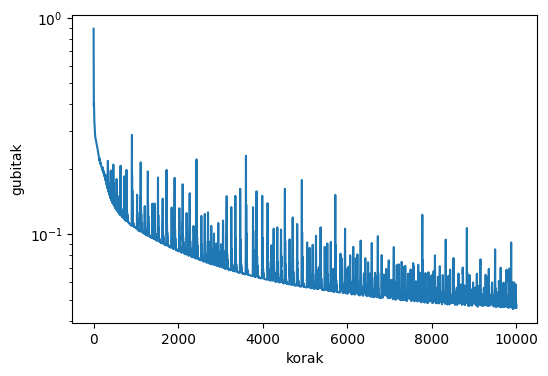

In [16]:
optm_ns = torch.optim.Adam(net_ns.parameters(), lr=1e-3)
loss_record_ns = []

for itr in range(10000):
    optm_ns.zero_grad()
    loss, loss_pde, loss_bc = ukupan_gubitak()
    loss.backward()
    optm_ns.step()
    loss_record_ns.append(loss.item())
    if itr % 1000 == 0:
        print(f'{itr:6d}  ukupno {loss.item():.4e}  fizika {loss_pde.item():.4e}  ivice {loss_bc.item():.4e}')

plt.figure(figsize=(6, 4))
plt.plot(loss_record_ns)
plt.yscale('log')
plt.xlabel('korak')
plt.ylabel('gubitak')
plt.show()

### 4.5 Rezultati posle Adama (u, v, p odozgo)

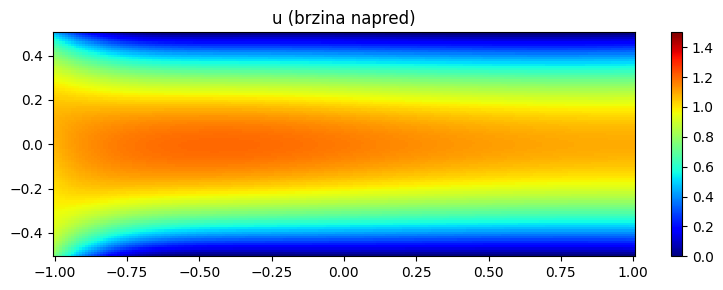

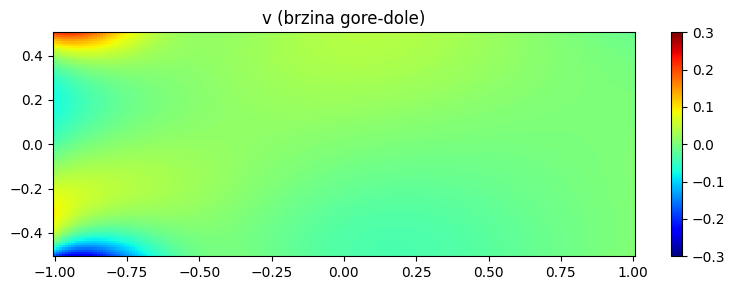

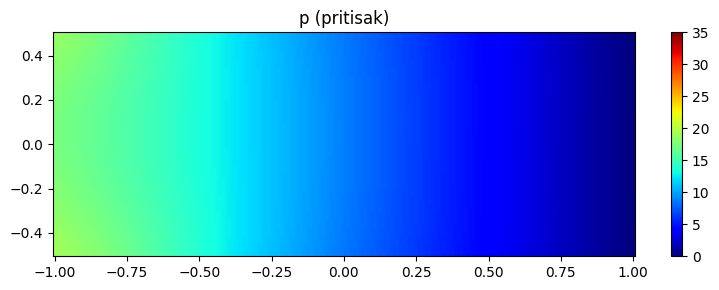

In [17]:
def nacrtaj_polja():
    nx, ny = 200, 100
    xs = np.linspace(-L/2, L/2, nx)
    ys = np.linspace(-D/2, D/2, ny)
    XX, YY = np.meshgrid(xs, ys)
    pts = torch.tensor(np.stack([XX.ravel(), YY.ravel()], axis=1), dtype=torch.float32, device=device)
    with torch.no_grad():
        res = net_ns(pts).cpu().numpy()

    imena = ['u (brzina napred)', 'v (brzina gore-dole)', 'p (pritisak)']
    color_legend = [[0, 1.5], [-0.3, 0.3], [0, 35]]
    for idx in range(3):
        plt.figure(figsize=(8, 3))
        plt.pcolormesh(XX, YY, res[:, idx].reshape(ny, nx), cmap='jet', shading='auto',
                       vmin=color_legend[idx][0], vmax=color_legend[idx][1])
        plt.colorbar()
        plt.title(imena[idx])
        plt.tight_layout()
        plt.show()

nacrtaj_polja()

### Komentar: rezultati posle Adama

Funkcija `nacrtaj_polja()` pravi pravilnu mrežu od 200 × 100 tačaka preko kanala i za svaku tačku pita mrežu za (u, v, p). Rezultat se prikazuje bojama. Skale boja su fiksne (u: 0–1,5; v: −0,3–0,3; p: 0–35), pa se grafici mogu porediti pre i posle L-BFGS.

**u (brzina napred):** uz zidove je 0, jer se tečnost lepi. Na ulazu je ravnomerna (≈1), a dalje se formira parabola sa maksimumom u sredini. Maksimum je oko 1,25 umesto 1,5 i ka izlazu blago opada, što znači da mreža još nije dovoljno istrenirana.

**v (brzina gore-dole):** skoro svuda ≈0, jer tečnost ide pravo. Kod ulaza se tečnost uz zidove pomera ka sredini: u gornjoj polovini v < 0, u donjoj v > 0. Crveno i plavo u levim uglovima je artefakt konflikta graničnih uslova (ulaz u = 1, zid u = 0).

**p (pritisak):** opada približno linearno od ≈18 na ulazu do 0 na izlazu i ne zavisi od y. Razlika pritisaka gura tečnost kroz kanal. Pad je manji od teorijskih ≈24, što je u skladu sa potcenjenom brzinom.

**Zaključak:** kvalitativno tačna slika toka. Kvantitativno su brzina u sredini i pad pritiska potcenjeni, što dodatni trening sa L-BFGS delimično popravlja (maksimum brzine 1,39).

### 4.6 Dodatni trening (L-BFGS)

L-BFGS je precizniji optimizer za fino doterivanje na kraju. Za razliku od Adama, on više puta zove funkciju gubitka u jednom koraku, pa mu se gubitak predaje kao funkcija (`closure`).

In [18]:
optm_lbfgs = torch.optim.LBFGS(net_ns.parameters(), lr=1.0, max_iter=3000,
                               tolerance_grad=1e-9, tolerance_change=1e-12,
                               history_size=50, line_search_fn='strong_wolfe')

def closure():
    optm_lbfgs.zero_grad()
    loss, _, _ = ukupan_gubitak()
    loss.backward()
    return loss

optm_lbfgs.step(closure)

loss, loss_pde, loss_bc = ukupan_gubitak()
print(f'Posle L-BFGS: ukupno {loss.item():.4e}  fizika {loss_pde.item():.4e}  ivice {loss_bc.item():.4e}')

Posle L-BFGS: ukupno 1.0063e-02  fizika 1.8374e-03  ivice 8.2257e-03


### 4.7 Rezultati posle Adam + L-BFGS

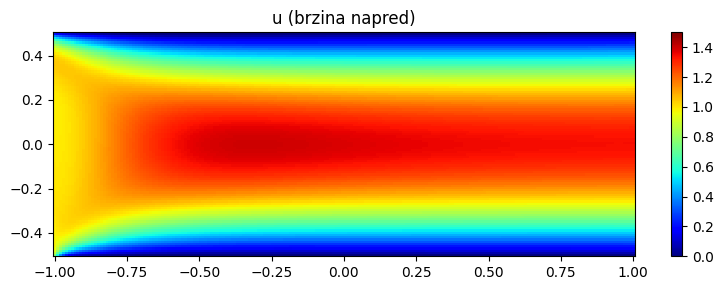

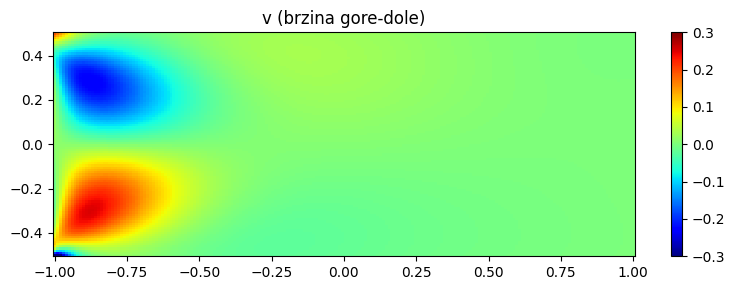

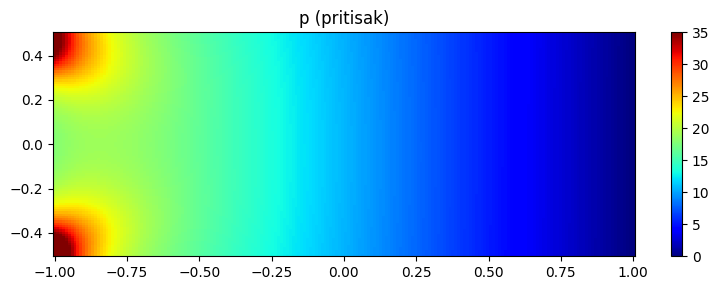

In [19]:
nacrtaj_polja()

### Komentar: dodatni trening L-BFGS

Adam koristi samo gradijent i pravi male korake, pa je robustan na početku treninga, ali pri kraju sporo napreduje i pravi šiljke u gubitku. L-BFGS pored gradijenta procenjuje i zakrivljenost funkcije gubitka iz poslednjih koraka (`history_size=50`). Zahvaljujući tome pravi veće i preciznije korake ka minimumu, a line search (`strong_wolfe`) bira dužinu koraka tako da gubitak zaista opada. Pošto L-BFGS u jednom koraku više puta računa gubitak, PyTorch-u se gubitak predaje kao funkcija (`closure`).

Standardna praksa kod PINN-ova je da se prvo trenira Adamom, koji mrežu dovodi blizu rešenja, a zatim L-BFGS-om, koji je fino dotera. Iz nasumičnog početka L-BFGS lako zaglavi.

**Rezultati:**

| | posle Adam-a | posle L-BFGS |
|---|---|---|
| ukupni gubitak | 0,047 | 0,011 |
| fizika | 0,0036 | 0,0024 |
| ivice | 0,043 | 0,0087 |
| brzina u sredini izlaza | ≈1,1–1,25 | 1,39 (tačno 1,5) |

Gubitak je pao oko 4 puta, najviše na graničnim uslovima. Profil brzine na izlazu ima tačan paraboličan oblik, sa nulom uz zidove i maksimumom u sredini, ali je maksimum oko 7 % niži od tačne vrednosti 1,5.

### 4.8 Provera: profil brzine na izlazu

Za potpuno razvijen tok između ploča tačan profil je parabola:

$$u(y) = \frac{3}{2}\,u_{in}\left[1 - \left(\frac{y}{D/2}\right)^2\right]$$

U sredini (y = 0) brzina je 1,5, a uz zidove 0.

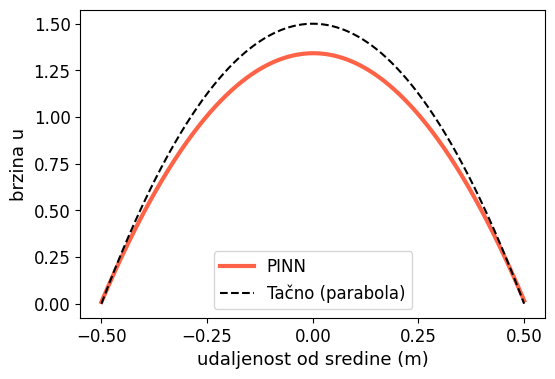

Brzina u sredini (PINN): 1.3419902  tačno: 1.5


In [20]:
y = np.linspace(-0.5, 0.5, 1000).reshape(-1, 1)
x = np.ones_like(y) * (L/2)
outlet = torch.tensor(np.hstack([x, y]), dtype=torch.float32, device=device)

analytic_solution = u_in * 1.5 * (1 - (y / (D/2))**2)
with torch.no_grad():
    PINN_solution = net_ns(outlet).cpu().numpy()


plt.figure(figsize=(6, 4))
plt.plot(y, PINN_solution[:, 0], c='tomato', linewidth=3, label='PINN')
plt.plot(y, analytic_solution, c='k', linestyle='--', label='Tačno (parabola)')
plt.xticks(np.linspace(-0.5, 0.5, 5), fontsize=12)
plt.yticks(np.linspace(0, 1.5, 7), fontsize=12)
plt.legend(fontsize=12)
plt.xlabel('udaljenost od sredine (m)', fontsize=13)
plt.ylabel('brzina u', fontsize=13)
plt.show()

print('Brzina u sredini (PINN):', PINN_solution[500, 0], ' tačno: 1.5')

---
### 4.9 Gubitak po delovima: uticaj pojedinačnih graničnih uslova

Ukupni gubitak je zbir 9 delova: 3 reziduala jednačina (fizika) i 6 graničnih uslova. Mreža se ovde trenira ponovo od početka (Adam, pa L-BFGS), uz praćenje **svakog dela posebno**, kako bi se videlo koji su uslovi najteži za ispunjavanje i kako na njih utiče L-BFGS.

In [21]:
def gubici_po_delovima():
    pde_u, pde_v, pde_cont = pde(X_domain)
    Yw, Yi, Yo = net_ns(X_wall), net_ns(X_inlet), net_ns(X_outlet)
    return {
        'fizika: kretanje x': mse(pde_u),
        'fizika: kretanje y': mse(pde_v),
        'fizika: kontinuitet': mse(pde_cont),
        'zid: u = 0': mse(Yw[:, 0]),
        'zid: v = 0': mse(Yw[:, 1]),
        'ulaz: u = 1': mse(Yi[:, 0] - u_in),
        'ulaz: v = 0': mse(Yi[:, 1]),
        'izlaz: p = 0': mse(Yo[:, 2]),
        'izlaz: v = 0': mse(Yo[:, 1]),
    }

FIZIKA = ['fizika: kretanje x', 'fizika: kretanje y', 'fizika: kontinuitet']
IVICE = ['zid: u = 0', 'zid: v = 0', 'ulaz: u = 1', 'ulaz: v = 0', 'izlaz: p = 0', 'izlaz: v = 0']
istorija = {k: [] for k in FIZIKA + IVICE}
koraci = []

def zapamti(d, n):
    for k, v in d.items():
        istorija[k].append(v.item())
    koraci.append(n)

In [22]:
torch.manual_seed(0)
layers = [nn.Linear(2, 64), nn.Tanh()]
for _ in range(4):
    layers += [nn.Linear(64, 64), nn.Tanh()]
layers += [nn.Linear(64, 3)]
net_ns = nn.Sequential(*layers).to(device)

N_ADAM, ZAPIS = 10000, 10
optm_ns = torch.optim.Adam(net_ns.parameters(), lr=1e-3)
for itr in range(N_ADAM):
    optm_ns.zero_grad()
    d = gubici_po_delovima()
    loss = sum(d.values())
    loss.backward()
    optm_ns.step()
    if itr % ZAPIS == 0:
        zapamti(d, itr)
    if itr % 1000 == 0:
        fiz = sum(d[k].item() for k in FIZIKA); ivi = sum(d[k].item() for k in IVICE)
        print(f'{itr:6d}  ukupno {loss.item():.3e}  fizika {fiz:.3e}  ivice {ivi:.3e}')

posle_adama = {k: v.item() for k, v in gubici_po_delovima().items()}

     0  ukupno 8.895e-01  fizika 1.391e-03  ivice 8.881e-01
  1000  ukupno 1.068e-01  fizika 1.320e-02  ivice 9.360e-02
  2000  ukupno 8.374e-02  fizika 7.748e-03  ivice 7.600e-02
  3000  ukupno 7.199e-02  fizika 6.497e-03  ivice 6.549e-02
  4000  ukupno 7.051e-02  fizika 5.885e-03  ivice 6.462e-02
  5000  ukupno 5.712e-02  fizika 4.213e-03  ivice 5.290e-02
  6000  ukupno 5.354e-02  fizika 4.249e-03  ivice 4.929e-02
  7000  ukupno 5.180e-02  fizika 4.542e-03  ivice 4.726e-02
  8000  ukupno 4.915e-02  fizika 4.294e-03  ivice 4.486e-02
  9000  ukupno 4.807e-02  fizika 5.031e-03  ivice 4.304e-02


In [23]:
optm_lbfgs = torch.optim.LBFGS(net_ns.parameters(), lr=1.0, max_iter=3000,
                               tolerance_grad=1e-9, tolerance_change=1e-12,
                               history_size=50, line_search_fn='strong_wolfe')
broj_eval = [0]

def closure():
    optm_lbfgs.zero_grad()
    d = gubici_po_delovima()
    loss = sum(d.values())
    loss.backward()
    if broj_eval[0] % ZAPIS == 0:
        zapamti(d, N_ADAM + broj_eval[0])
    broj_eval[0] += 1
    return loss

optm_lbfgs.step(closure)
posle_lbfgs = {k: v.item() for k, v in gubici_po_delovima().items()}
print('L-BFGS izračunavanja gubitka:', broj_eval[0])

L-BFGS izračunavanja gubitka: 3181


In [24]:
def zbir(d, kljucevi): return sum(d[k] for k in kljucevi)
uk_a, uk_l = zbir(posle_adama, FIZIKA + IVICE), zbir(posle_lbfgs, FIZIKA + IVICE)

print(f"{'deo gubitka':24s} {'posle Adama':>12s} {'udeo':>7s} {'posle L-BFGS':>13s} {'udeo':>7s} {'smanjenje':>10s}")
for k in FIZIKA + IVICE:
    a, l = posle_adama[k], posle_lbfgs[k]
    print(f'{k:24s} {a:12.2e} {a/uk_a:7.1%} {l:13.2e} {l/uk_l:7.1%} {a/l:9.1f}x')
print('-' * 80)
for ime, kl in [('UKUPNO fizika', FIZIKA), ('UKUPNO ivice', IVICE), ('UKUPNO', FIZIKA + IVICE)]:
    a, l = zbir(posle_adama, kl), zbir(posle_lbfgs, kl)
    print(f'{ime:24s} {a:12.2e} {a/uk_a:7.1%} {l:13.2e} {l/uk_l:7.1%} {a/l:9.1f}x')

deo gubitka               posle Adama    udeo  posle L-BFGS    udeo  smanjenje
fizika: kretanje x           1.03e-03    2.2%      3.30e-04    3.3%       3.1x
fizika: kretanje y           3.35e-04    0.7%      4.20e-04    4.2%       0.8x
fizika: kontinuitet          3.04e-03    6.4%      1.12e-03   11.2%       2.7x
zid: u = 0                   1.64e-02   34.5%      2.43e-03   24.4%       6.7x
zid: v = 0                   5.58e-03   11.8%      1.69e-03   17.0%       3.3x
ulaz: u = 1                  1.54e-02   32.5%      2.81e-03   28.2%       5.5x
ulaz: v = 0                  4.34e-03    9.2%      1.14e-03   11.4%       3.8x
izlaz: p = 0                 1.30e-03    2.7%      1.05e-05    0.1%     123.7x
izlaz: v = 0                 1.10e-05    0.0%      6.24e-06    0.1%       1.8x
--------------------------------------------------------------------------------
UKUPNO fizika                4.41e-03    9.3%      1.87e-03   18.7%       2.4x
UKUPNO ivice                 4.31e-02   90.7%     

### Komentar: koliko koji deo gubitka utiče

Ukupni gubitak je zbir 9 delova: 3 reziduala jednačina (fizika) i 6 graničnih uslova. Tabela pokazuje vrednost svakog dela, njegov udeo u ukupnom gubitku i koliko puta ga je L-BFGS smanjio.

**1. Gubitak skoro u potpunosti potiče od graničnih uslova.**
Posle Adama granični uslovi čine **90,7 %** gubitka, a fizika samo 9,3 %. Mreža jednačine unutar kanala zadovoljava dobro, a najviše greši na ivicama.

**2. Najveći problem su dva uslova u konfliktu: zid u = 0 i ulaz u = 1.**
Posle Adama ta dva uslova zajedno daju **67 %** gubitka (34,5 % + 32,5 %). U uglovima kod ulaza (x = −1, y = ±0,5) tačka pripada i zidu i ulazu: zid traži u = 0, a ulaz u = 1. Mreža ne može da ispuni oba, pa grešku mora da „podeli“ između njih.

**3. Uslovi na izlazu su skoro savršeno ispunjeni.**
Izlaz p = 0 i v = 0 zajedno čine samo 2,7 % gubitka posle Adama i 0,2 % posle L-BFGS-a. Na izlazu nema konflikta uslova.

**4. Među jednačinama najteža je jednačina kontinuiteta** (6,4 % posle Adama, 11,2 % posle L-BFGS-a), dok su jednačine kretanja zadovoljene bolje.

**5. L-BFGS najviše popravlja granične uslove.**
Ukupni gubitak pada sa 4,75·10⁻² na 9,96·10⁻³ (**4,8× manje**). Granični uslovi se smanjuju **5,3×**, a fizika samo **2,4×**. Zato udeo fizike raste sa 9,3 % na 18,7 %: fizika se nije pogoršala, već su se granični uslovi znatno popravili. Najveće smanjenje ima pritisak na izlazu (**124×**), a dva konfliktna uslova se smanjuju 6,7× (zid u = 0) i 5,5× (ulaz u = 1).

**6. Konflikt u uglovima ostaje i posle L-BFGS-a.**
Zid u = 0 i ulaz u = 1 i dalje čine više od polovine gubitka (24,4 % + 28,2 % = **52,6 %**). Nijedan optimizer ne može da ispuni dva suprotna uslova u istoj tački. Mogući sledeći korak bio bi ulazni profil brzine koji uz zidove i sam ide na 0, čime bi se konflikt uklonio.

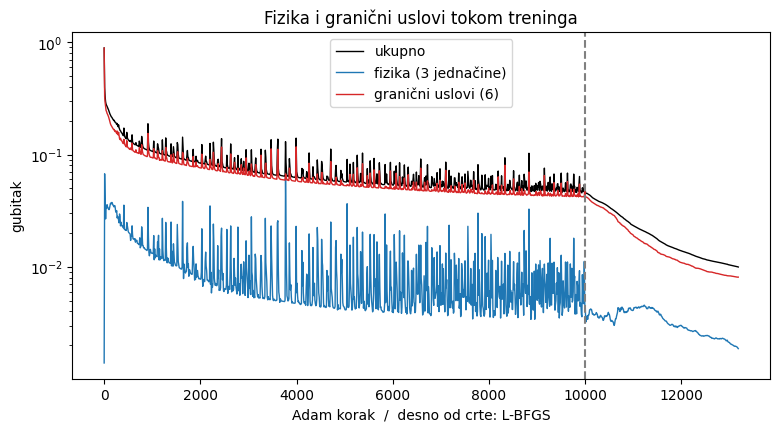

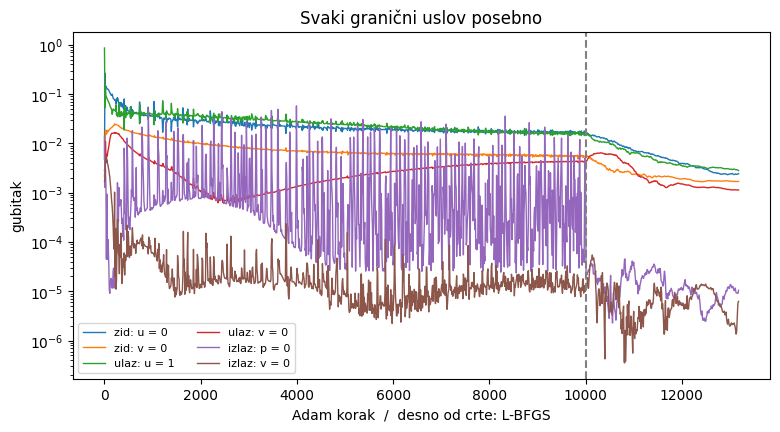

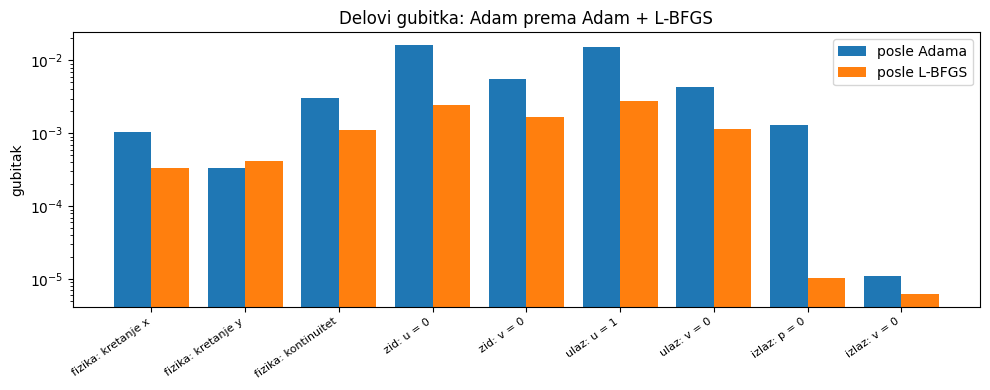

In [25]:
x = np.array(koraci)
fiz = np.sum([istorija[k] for k in FIZIKA], axis=0)
ivi = np.sum([istorija[k] for k in IVICE], axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(x, fiz + ivi, color='black', lw=1, label='ukupno')
ax.semilogy(x, fiz, color='tab:blue', lw=1, label='fizika (3 jednačine)')
ax.semilogy(x, ivi, color='tab:red', lw=1, label='granični uslovi (6)')
ax.axvline(N_ADAM, color='gray', ls='--')
ax.set_xlabel('Adam korak  /  desno od crte: L-BFGS'); ax.set_ylabel('gubitak')
ax.legend(); ax.set_title('Fizika i granični uslovi tokom treninga')
plt.show()



fig, ax = plt.subplots(figsize=(9, 4.5))
for k in IVICE:
    ax.semilogy(x, istorija[k], lw=1, label=k)
ax.axvline(N_ADAM, color='gray', ls='--')
ax.set_xlabel('Adam korak  /  desno od crte: L-BFGS'); ax.set_ylabel('gubitak')
ax.legend(fontsize=8, ncol=2); ax.set_title('Svaki granični uslov posebno')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
imena = FIZIKA + IVICE
pos = np.arange(len(imena))
ax.bar(pos - 0.2, [posle_adama[k] for k in imena], 0.4, label='posle Adama')
ax.bar(pos + 0.2, [posle_lbfgs[k] for k in imena], 0.4, label='posle L-BFGS')
ax.set_yscale('log'); ax.set_xticks(pos); ax.set_xticklabels(imena, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('gubitak'); ax.legend(); ax.set_title('Delovi gubitka: Adam prema Adam + L-BFGS')
plt.tight_layout(); plt.show()

### 4.10 Gde tačno nastaje gubitak ivica

Gubitak svakog graničnog uslova je **prosek** grešaka po tačkama, pa se iz njega ne vidi da li sve tačke
greše malo ili nekoliko tačaka greši mnogo. Zato se računa doprinos **svake granične tačke posebno**,
a tačke se prikazuju na kanalu (veličina i boja tačke = doprinos gubitku).

**Rezultat:**
- svih 10 najgorih tačaka su tačke zida ili ulaza na ulaznom kraju, na 0,013–0,076 od ulaznih uglova;
  zajedno nose 84 % gubitka ivica, a samo prve dve 52 %;
- 10 od 200 tačaka (5 %) na manje od 0,05 od uglova nosi **82 %** gubitka ivica,
  15 tačaka (8 %) do 0,1 nosi 89 %, a 26 tačaka (13 %) do 0,2 nosi 95 %;
- izlaz i zidovi daleko od ulaza su praktično savršeni (greške ~10⁻⁶);
- isti procenti (82 / 89 / 94–95 %) dobijeni su i u nezavisnom pokretanju sa drugačijim rasporedom tačaka,
  pa je ovo osobina postavke, a ne slučajnost.

**Zašto:** u uglu zid traži u = 0, a ulaz u = 1. Mreža je glatka funkcija i u uglu ima jednu vrednost,
pa bira kompromis: u ovom pokretanju u ≈ 0,22 u gornjem uglu (gde je bliže više tačaka zida)
i u ≈ 0,77 u donjem (gde je bliže više tačaka ulaza). Tako greši prema oba uslova istovremeno.
Tačke ulaza imaju veću težinu od tačaka zida (prosek se uzima nad 30, a ne nad 140 tačaka),
pa je najgora pojedinačna tačka ulazna tačka na y = 0,46, usred naglog pada profila.

**Posledice:** zbog naglog pada u uz zid, jednačina kontinuiteta tera v da odstupi od nule u uglovima
(do −0,43), pa se konflikt prenosi i na uslove v = 0. Rezidual jednačina je takođe najveći
na ulaznom kraju kanala. Problem je lokalan: za x > −0,8 svi uslovi na zidovima su ispunjeni.

**Zaključak:** gubitak ivica nije ravnomerno raspoređen i ne potiče od toga što mreža loše uči.
On je posledica **protivrečne postavke** graničnih uslova u dve tačke.

In [29]:
with torch.no_grad():
    Yw, Yi, Yo = net_ns(X_wall), net_ns(X_inlet), net_ns(X_outlet)

# kvadrat greške za svaku tačku (pre uzimanja proseka u mse)
gr_zid   = (Yw[:, 0]**2 + Yw[:, 1]**2).cpu().numpy()             # zid:   u = 0 i v = 0
gr_ulaz  = ((Yi[:, 0] - u_in)**2 + Yi[:, 1]**2).cpu().numpy()    # ulaz:  u = 1 i v = 0
gr_izlaz = (Yo[:, 2]**2 + Yo[:, 1]**2).cpu().numpy()             # izlaz: p = 0 i v = 0

# doprinos tačke ukupnom gubitku: mse deli sa brojem tačaka u svojoj grupi
dopr_zid, dopr_ulaz, dopr_izlaz = gr_zid / len(X_wall), gr_ulaz / len(X_inlet), gr_izlaz / len(X_outlet)

Xw, Xi, Xo = X_wall.cpu().numpy(), X_inlet.cpu().numpy(), X_outlet.cpu().numpy()
sve_tacke = np.vstack([Xw, Xi, Xo])
sve_dopr  = np.concatenate([dopr_zid, dopr_ulaz, dopr_izlaz])
sve_grupe = np.array(['zid'] * len(Xw) + ['ulaz'] * len(Xi) + ['izlaz'] * len(Xo))

# rastojanje svake tačke do najbližeg ulaznog ugla (-1, -0.5) ili (-1, 0.5)
uglovi = np.array([[-L/2, -D/2], [-L/2, D/2]])
rast = np.min(np.linalg.norm(sve_tacke[:, None, :] - uglovi[None, :, :], axis=2), axis=1)

# 10 najgorih tačaka
red = np.argsort(sve_dopr)[::-1]
ukupno = sve_dopr.sum()
print(f"{'#':>2s} {'grupa':>6s} {'x':>7s} {'y':>7s} {'do ugla':>8s} {'udeo u gubitku ivica':>22s}")
for k, i in enumerate(red[:10]):
    print(f'{k+1:2d} {sve_grupe[i]:>6s} {sve_tacke[i,0]:7.3f} {sve_tacke[i,1]:7.3f} {rast[i]:8.3f} {sve_dopr[i]/ukupno:21.1%}')

# koliko gubitka dolazi iz okoline ulaznih uglova
for r in [0.05, 0.1, 0.2]:
    blizu = rast < r
    print(f'tačke na rastojanju < {r} od ulaznih uglova: {blizu.sum():3d} od {len(rast)} '
          f'({blizu.mean():.0%} tačaka) → {sve_dopr[blizu].sum()/ukupno:.0%} gubitka ivica')

 #  grupa       x       y  do ugla   udeo u gubitku ivica
 1   ulaz  -1.000   0.460    0.040                 29.2%
 2    zid  -0.980  -0.500    0.020                 23.1%
 3    zid  -0.987   0.500    0.013                  5.1%
 4    zid  -0.950  -0.500    0.050                  4.6%
 5    zid  -0.981   0.500    0.019                  4.3%
 6    zid  -0.980   0.500    0.020                  4.2%
 7    zid  -0.977   0.500    0.023                  3.9%
 8   ulaz  -1.000  -0.424    0.076                  3.7%
 9   ulaz  -1.000  -0.481    0.019                  3.4%
10   ulaz  -1.000  -0.480    0.020                  2.6%
tačke na rastojanju < 0.05 od ulaznih uglova:  10 od 200 (5% tačaka) → 82% gubitka ivica
tačke na rastojanju < 0.1 od ulaznih uglova:  15 od 200 (8% tačaka) → 89% gubitka ivica
tačke na rastojanju < 0.2 od ulaznih uglova:  26 od 200 (13% tačaka) → 95% gubitka ivica


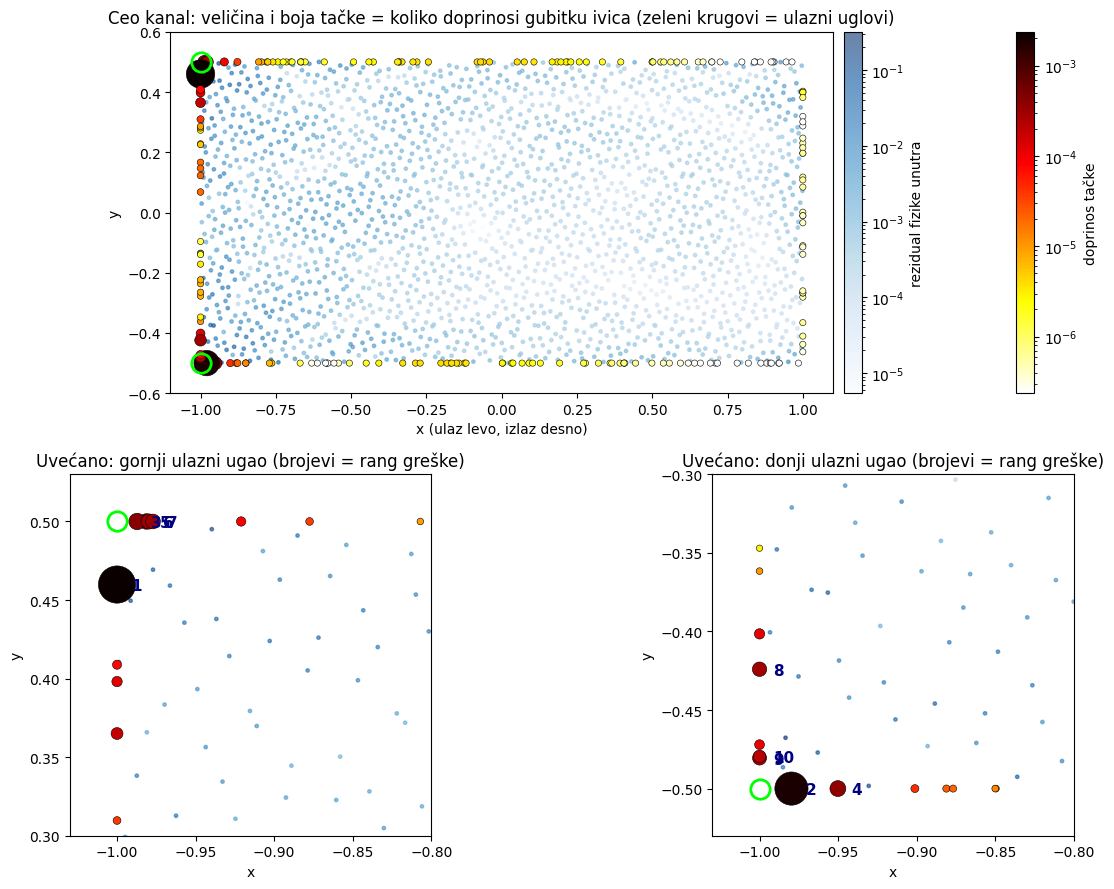

In [27]:
from matplotlib.colors import LogNorm

# rezidual fizike u unutrašnjim tačkama (za pozadinu)
pde_u, pde_v, pde_cont = pde(X_domain)
rez = (pde_u**2 + pde_v**2 + pde_cont**2).detach().cpu().numpy().ravel()
Xd = X_domain.cpu().numpy()
norma = LogNorm(vmin=sve_dopr.max() * 1e-4, vmax=sve_dopr.max())

def crtaj(ax, velicina=400, brojevi=0):
    sc0 = ax.scatter(Xd[:, 0], Xd[:, 1], c=rez, s=6, cmap='Blues', norm=LogNorm(), alpha=0.6)
    sc = ax.scatter(sve_tacke[:, 0], sve_tacke[:, 1], c=np.maximum(sve_dopr, norma.vmin), cmap='hot_r', norm=norma,
                    s=20 + velicina * sve_dopr / sve_dopr.max(), edgecolor='k', linewidth=0.4, zorder=3)
    for k, i in enumerate(red[:brojevi]):
        ax.annotate(str(k + 1), sve_tacke[i], xytext=(10, -4), textcoords='offset points',
                    fontsize=11, weight='bold', color='navy', zorder=4)
    ax.plot(*uglovi.T, 'o', ms=14, mfc='none', mec='lime', mew=2, zorder=5)
    ax.set_aspect('equal')
    return sc0, sc

fig = plt.figure(figsize=(13, 9))
ax  = fig.add_subplot(2, 1, 1)
sc0, sc = crtaj(ax)
ax.set_xlim(-L/2 - 0.1, L/2 + 0.1); ax.set_ylim(-D/2 - 0.1, D/2 + 0.1)
ax.set_xlabel('x (ulaz levo, izlaz desno)'); ax.set_ylabel('y')
ax.set_title('Ceo kanal: veličina i boja tačke = koliko doprinosi gubitku ivica (zeleni krugovi = ulazni uglovi)')
fig.colorbar(sc, ax=ax, label='doprinos tačke', pad=0.01)
fig.colorbar(sc0, ax=ax, label='rezidual fizike unutra', pad=0.01)

for j, (y0, ime) in enumerate([(D/2, 'gornji ulazni ugao'), (-D/2, 'donji ulazni ugao')]):
    axz = fig.add_subplot(2, 2, 3 + j)
    crtaj(axz, velicina=700, brojevi=10)
    axz.set_xlim(-L/2 - 0.03, -L/2 + 0.2)
    axz.set_ylim(y0 - 0.2, y0 + 0.03) if y0 > 0 else axz.set_ylim(y0 - 0.03, y0 + 0.2)
    axz.set_xlabel('x'); axz.set_ylabel('y'); axz.set_title('Uvećano: ' + ime + ' (brojevi = rang greške)')
plt.tight_layout(); plt.show()